In [77]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
# import plot_toe_eddies as plot
import class_EDDIES as ed
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as ticker

In [85]:
dates_chl = ['20260701', '20260702', '20260703', '20260704', '20260705', '20260706']

chl = {}

for date_chl in dates_chl:
    chl[date_chl] = xr.open_dataset(f"Y:\\MD252_WHIRLS\\DAILY_adt_sst_toeddies_data\\CHL\\{date_chl}_CLS_CHL.nc").chl_a[0::]

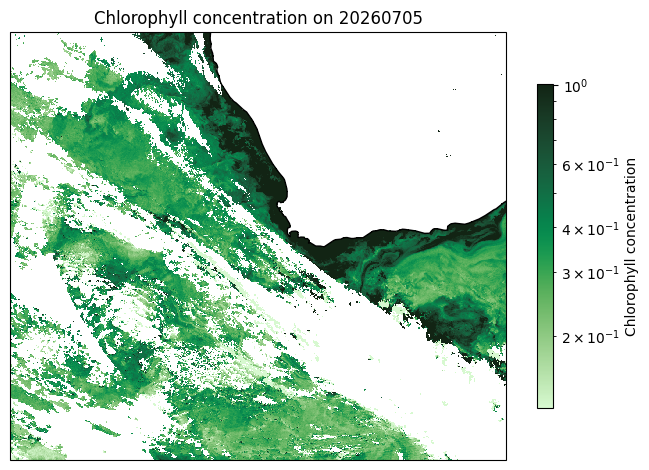

In [86]:
# chl['20260706'].squeeze().plot()

day = '20260705'

log_min = -0.9
log_max = 0.001
lats_chl = chl[day]['latitude'][:]
lons_chl = chl[day]['longitude'][:]

fig, ax = plt.subplots(
    subplot_kw={'projection': ccrs.PlateCarree()},
    figsize=(8, 6)
)

mesh = ax.pcolormesh(
    lons_chl,
    lats_chl,
    10**chl[day].squeeze(),
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.algae,
    norm=LogNorm(vmin=10**log_min, vmax=10**log_max)
)

# Add coastlines and colorbar
ax.coastlines()
cbar = plt.colorbar(mesh, ax=ax, orientation='vertical', shrink=0.7)
cbar.set_label("Chlorophyll concentration")

plt.title(f"Chlorophyll concentration on {day}")
plt.show()


In [3]:
# wget -O "C:\Users\erica\Downloads\20260702_CLS_CHL_5d.nc" https://thredds-x.ipsl.fr/thredds/fileServer/WHIRLS/SATELLITE/CHL/20260704_CLS_CHL_5d.nc

In [87]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return hours, minutes

In [128]:
july_day = '06'

date = f'2026-07-{july_day}'
date_chl = f"202607{july_day}"

yr = date[0:4]
mnth = date[5:7]
day = date[-2:]
sab_1 = (11.892700, -39.216100)
sab_2 = (11.541100, -38.4758007)
sab_3 = (11.1800, -39.24000)

glider_deployment = (11.54, -37.41)
s1_x, s1_y = sab_1
s2_x, s2_y = sab_2
s3_x, s3_y = sab_3

In [129]:
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]

station_1 = (dm_to_dd(16, 38.247), dm_to_dd(34, 29.976, True))
station_2 = (dm_to_dd(15, 25.675), dm_to_dd(34, 29.963, True))
station_3 = (dm_to_dd(11, 38.167), dm_to_dd(37, 24.128, True))
station_4 = (dm_to_dd(11,57.498), dm_to_dd(38, 9.637, True))
station_5 = (dm_to_dd(11,53.235), dm_to_dd(39, 12.933, True))
station_6 = (dm_to_dd(11,32.443), dm_to_dd(38, 28.558, True))
station_7 = (dm_to_dd(11,39.051), dm_to_dd(39, 23.478, True))
station_8 = (dm_to_dd(11,38.575), dm_to_dd(39, 23.533, True))

glider1 = (11.54, -37.41) # 283 and 284 have been deployed
#284(microrider) 01-07-2026 @ 11:30 UTC -37.4138 11.6210
glider2 = ()
#283(suna) 03-07-2026 @ 11:31 UTC -38.4683 11.5483

In [130]:
##### POSITION VARIABLES #####
ft=10
small_box = True
if small_box is True:
    lon_min, lon_max, lat_min, lat_max = 9, 17, -40, -34
    pos_west,pos_east,pos_south,pos_north  = 9, 17, -40,-34 
    vmin_adt = -0.2
    vmax_adt = 1.2
    title="zoom"
else:
    lon_min, lon_max, lat_min, lat_max = 6, 23, -44, -32
    pos_west,pos_east,pos_south,pos_north  = 6, 23, -44,-32  #Reset the area
    title=""
    vmin_adt = -0.25
    vmax_adt = 1.55
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [131]:
dir = f"Y:\\MD252_WHIRLS\\REP\\TOEddies_WHIRLS\\"
# sst_path = dir + f"Eddies\{date}\sst\{date.replace("-", "")}_CLS_SST.nc"

dir_adcp = "Y:\\MD252_WHIRLS\\ADCP_FROM_XAVIER\\MD2_OS38_WHIRLS-2026_120s_oceansites.nc"
dir_eddies = dir + f"Eddies\\{date}\\{date}_toeddies\\"

save_fig = dir + f"daily_figures\\{date}\\"

if not os.path.isdir(save_fig):
    os.makedirs(save_fig)

fname_bathy = "Y:\\MD252_WHIRLS\\REP\\TOEddies_WHIRLS\\bathymetry\\etopo2.nc"
ctd_path = "Y:\\MD252_WHIRLS\\CTD\\data"

adt_path= f"Y:\\MD252_WHIRLS\\REP\\TOEddies_WHIRLS\\Eddies\\{date}\\ssh\\{date}_cmems_data.nc"


# chl_path = f"Y:\\MD252_WHIRLS\\REP\\TOEddies_WHIRLS\\Eddies\\{date}\\chl\\{date_chl}_CLS_CHL.nc"
chl_path = f"Y:\\MD252_WHIRLS\\DAILY_adt_sst_toeddies_data\\CHL\\{date_chl}_CLS_CHL_5d.nc"

In [132]:
adt_data = nc.Dataset(adt_path)
chl_data = nc.Dataset(chl_path)

FileNotFoundError: [Errno 2] No such file or directory: 'Y:\\MD252_WHIRLS\\REP\\TOEddies_WHIRLS\\Eddies\\2026-07-06\\ssh\\2026-07-06_cmems_data.nc'

In [ ]:
lats = adt_data['latitude'][:]
lons = adt_data['longitude'][:]
time = adt_data['time'][:]
adt = adt_data['adt'][:]
ugos = np.squeeze(adt_data['ugos'][:])
vgos = np.squeeze(adt_data['vgos'][:])
current_mag = np.sqrt(ugos**2 + vgos**2)

C:\Users\erica\AppData\Local\Temp\ipykernel_34928\1840043835.py:7: RuntimeWarning: invalid value encountered in sqrt
  current_mag = np.sqrt(ugos**2 + vgos**2)


In [ ]:
adt_data['ugos']

<class 'netCDF4.Variable'>
int32 ugos(time, latitude, longitude)
    _FillValue: -2147483647
    grid_mapping: crs
    long_name: Absolute geostrophic velocity: zonal component
    standard_name: surface_geostrophic_eastward_sea_water_velocity
    units: m/s
    coordinates: longitude latitude
    scale_factor: 0.0001
unlimited dimensions: 
current shape = (1, 156, 180)
filling on

In [133]:
chl = chl_data['chl_a'][:]

lats_chl = chl_data['latitude'][:]
lons_chl = chl_data['longitude'][:]
time_chl = chl_data['time'][:]
chl = np.squeeze(chl)

In [134]:
path_nav = "Y:\\MD252_WHIRLS\\REP\\TOEddies_WHIRLS\\NAV\\"

files = sorted([f for f in os.listdir(path_nav) if f.endswith('.nav')])

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)

clean_date = date.replace("-", "")

# Find the exact index matching your day
slice_index = None
for idx, file in enumerate(files):
    if clean_date in file:
        slice_index = idx
        break

# 3. Slice and calculate coordinates
if slice_index is not None:
    # Slices perfectly from day 1 up to your target day
    lat_bato = np.concatenate(lat_list[:slice_index + 1])
    longs_bato = np.concatenate(lon_list[:slice_index + 1])
    
    ship_center = (longs_bato[-1], lat_bato[-1])
    ship_x, ship_y = ship_center
    
else:
    print(f"Error: Could not find any files matching the date {date}")

In [135]:
# lats_sst = sst_data['NbLatitudes']
# lons_sst = sst_data['NbLongitudes']
# time = sst_data['time']
# sst = sst_data['Grid_0001']

# sst = np.where(sst==np.nan, 0, sst)

In [136]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [137]:
depth_subset = np.where(depth_subset > 0, 0, depth_subset)

In [138]:
files = os.listdir(dir_eddies)
for fname in files:
    if "anti" in fname:
        if "maxspeed" in fname:
            gdf_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdf_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdf_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")
    else:
        if "maxspeed" in fname:
            gdfcyc_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdfcyc_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdfcyc_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")

In [139]:
speed_knots = 6.0
stop_hours = 2.0

points = [
    (ship_x, ship_y),
    (s1_x, s1_y),
    (s2_x, s2_y),
    (s3_x, s3_y),
]

total_time = 0.0
times = []  # cumulative arrival times

for i in range(1, len(points)):
    lon1, lat1 = points[i-1]
    lon2, lat2 = points[i]

    dist_nm = haversine_nm(lon1, lat1, lon2, lat2)
    travel_time = dist_nm / speed_knots  # hours

    total_time += travel_time

    # arrival at point i
    times.append(total_time)

    # add stop time except after final point
    if i < len(points) - 1:
        total_time += stop_hours
curr_t = datetime.now()

In [140]:
# plt.imshow(chl, cmap="viridis", origin="lower")
# plt.colorbar(label="Value")
# plt.show()

In [141]:
chl = chl.squeeze()

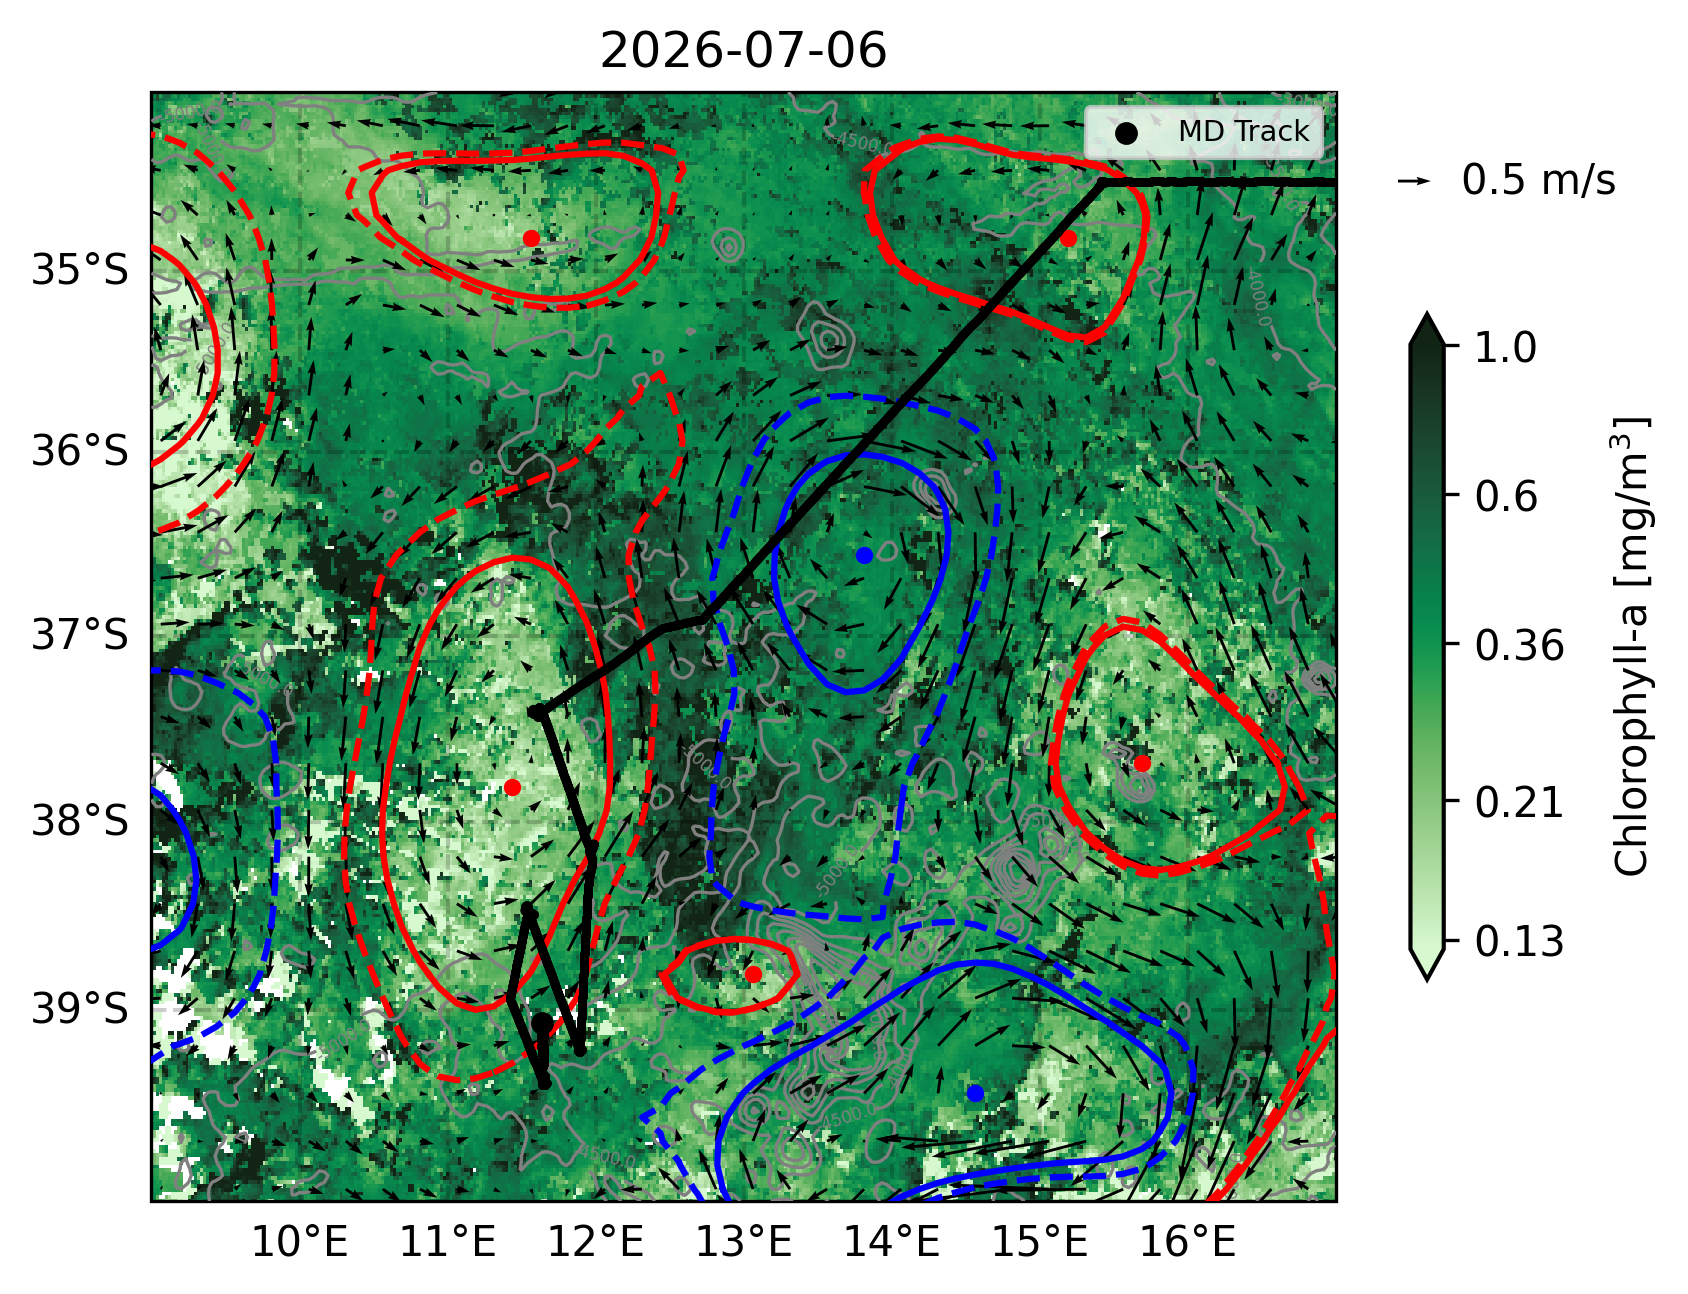

In [142]:
fig = plt.figure(dpi=300)


ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

log_min = -0.9
log_max = 0.001

c2 = ax0.pcolormesh(
    lons_chl, 
    lats_chl, 
    10**chl, 
    transform=crs, 
    cmap=cmocean.cm.algae, 
    norm=LogNorm(vmin=10**log_min, vmax=10**log_max)
)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6, extend='both')
manual_ticks = np.round(np.logspace(log_min, log_max, num=5), 2)
cbar.set_ticks(manual_ticks)
cbar.set_ticklabels([str(tick) for tick in manual_ticks])
cbar.ax.yaxis.set_minor_locator(ticker.NullLocator())
cbar.ax.tick_params(labelsize=10)
cbar.set_label('Chlorophyll-a [mg/m$^3$]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)


# ADT contours
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='k', zorder=100, transform=crs, label="MD Track")

h, m = format_time(times[0])
upd_t = curr_t + timedelta(hours=h, minutes=m)

h, m = format_time(times[2])
upd_t = curr_t + timedelta(hours=h, minutes=m)

arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='k', zorder=90)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_chl.png")
plt.savefig("C:\\Users\\erica\\OneDrive\\Desktop\\PhD\\WHIRLS cruise\\chl maps\\" + f"{date}_chl.png")

In [ ]:
### add a 2d map of surface chl overlapped on this 2d map (ask clara)